# Initial Model Training

In [1]:
import pandas as pd
from pathlib import Path
import pmdarima as pm
import time
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt
import joblib

from agripharm_track3_ethnohack_2026.forecasting.utils import PROCESSED_DATA_DIR, MODELS_DIR, OUTPUT_DATA_DIR

In [2]:
data = pd.read_csv(PROCESSED_DATA_DIR / Path("initial_train_data.csv"))
data

,Unnamed: 0,M04AC01,C01AA05,S01EB01,A04AD01,S01FA01
0,2012-01-01,190768,236125,14681,1097,19757
1,2012-02-01,174553,217493,13736,1114,19250
2,2012-03-01,196767,230538,15573,1287,20112
3,2012-04-01,186323,220449,15081,977,19278
4,2012-05-01,200524,234628,16332,1237,18950
...,...,...,...,...,...,...
170,2026-03-01,120947,50798,11693,2477,20972
171,2026-04-01,113123,47271,10208,2350,19456
172,2026-05-01,104976,44334,9561,1975,17155
173,2026-06-01,133152,50094,11440,2165,20588


In [3]:
TEST_MONTHS = 12
TRAIN_MONTHS = len(data) - TEST_MONTHS

train_data = data.iloc[:TRAIN_MONTHS]
test_data = data.iloc[TRAIN_MONTHS:]

print(f"Train set size: {train_data.shape[0]} months")
print(f"Test set size: {test_data.shape[0]} months")

Train set size: 163 months
Test set size: 12 months


In [4]:
data.columns

Index(['Unnamed: 0', 'M04AC01', 'C01AA05', 'S01EB01', 'A04AD01', 'S01FA01'], dtype='str')

In [5]:
codes = data.columns[1:]

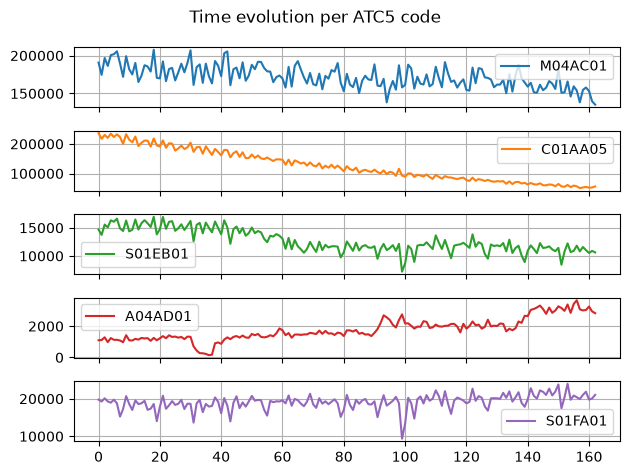

In [6]:
train_data.plot(
    subplots=True, 
    title="Time evolution per ATC5 code",
    grid=True,
)
plt.tight_layout()
plt.show()

In [7]:
models = {}
forecasts = {}

for code in codes:
    print(f"\n===== SARIMA training for ATC5: {code} =====")
    start_time = time.perf_counter()
    model = pm.auto_arima(
        train_data[code],
        seasonal=True,
        m=12, # 12 months per year
        d=1, D=1, # differetiation for stability and seasonality
        trace=False,
        error_action="ignore",
        suppress_warnings=True,
        stepwise=True,
    )
    end_time = time.perf_counter()
    print(f"Training took: {(end_time-start_time):.2f} seconds")
    models[code] = model
    forecasts[code] = model.predict(n_periods=TEST_MONTHS)
    print(f"Best model: {model.order} x {model.seasonal_order}")


===== SARIMA training for ATC5: M04AC01 =====
Training took: 17.65 seconds
Best model: (1, 1, 0) x (0, 1, 2, 12)

===== SARIMA training for ATC5: C01AA05 =====
Training took: 8.07 seconds
Best model: (0, 1, 1) x (0, 1, 0, 12)

===== SARIMA training for ATC5: S01EB01 =====
Training took: 118.14 seconds
Best model: (3, 1, 3) x (1, 1, 2, 12)

===== SARIMA training for ATC5: A04AD01 =====
Training took: 29.69 seconds
Best model: (1, 1, 1) x (0, 1, 1, 12)

===== SARIMA training for ATC5: S01FA01 =====
Training took: 14.33 seconds
Best model: (0, 1, 1) x (0, 1, 1, 12)


In [8]:
for code in codes:
    y_true = test_data[code]
    y_pred = forecasts[code]

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true-y_pred) / y_true)) * 100

    print(f"ATC5: {code} | RMSE: {rmse:.2f} | MAPE: {mape:.2f}%")

ATC5: M04AC01 | RMSE: 15869.64 | MAPE: 13.37%
ATC5: C01AA05 | RMSE: 2963.84 | MAPE: 4.20%
ATC5: S01EB01 | RMSE: 350.78 | MAPE: 2.85%
ATC5: A04AD01 | RMSE: 630.16 | MAPE: 25.64%
ATC5: S01FA01 | RMSE: 1869.32 | MAPE: 8.76%


The models for 'C01AA05', 'S01EB01', 'S01FA01' look good enough for now.

The models for 'M04AC01', 'A04AD01' look bad. Let's plot the whole dataset and the predictions to gain insights 

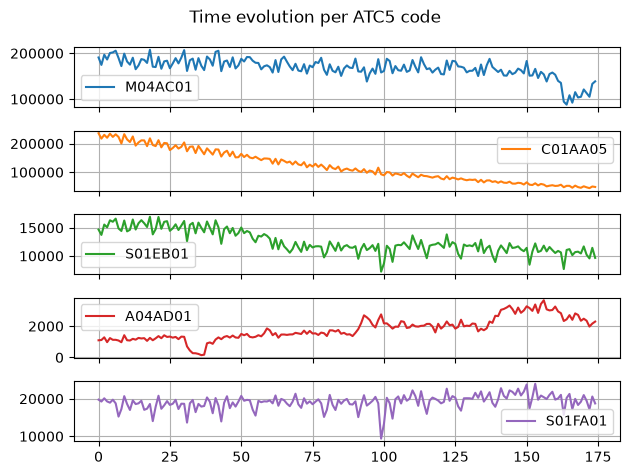

In [9]:
data.plot(
    subplots=True, 
    title="Time evolution per ATC5 code",
    grid=True,
)
plt.tight_layout()
plt.show()

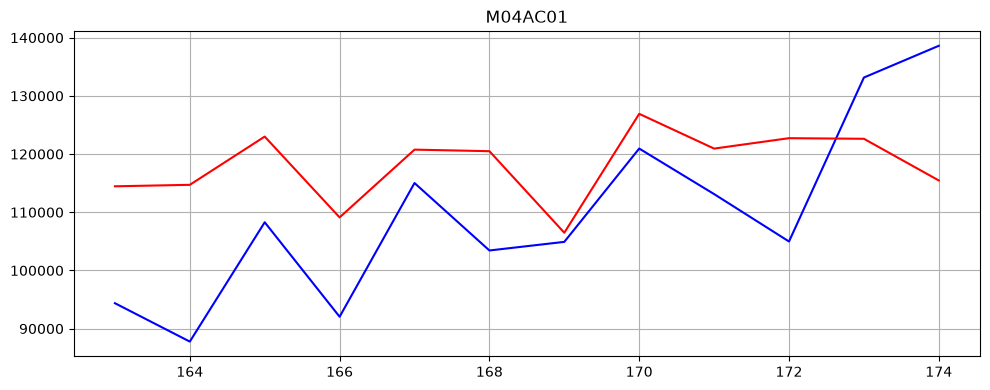

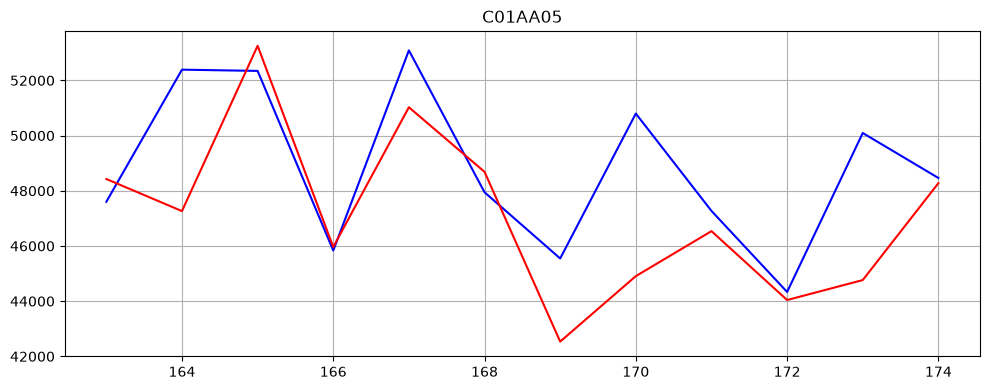

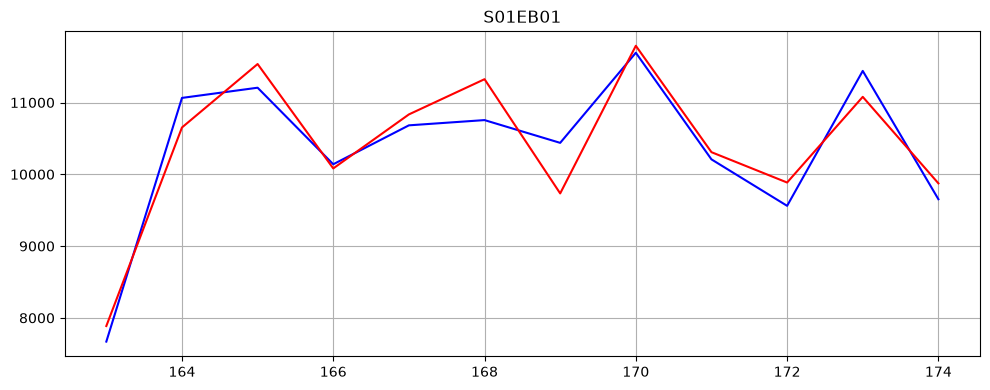

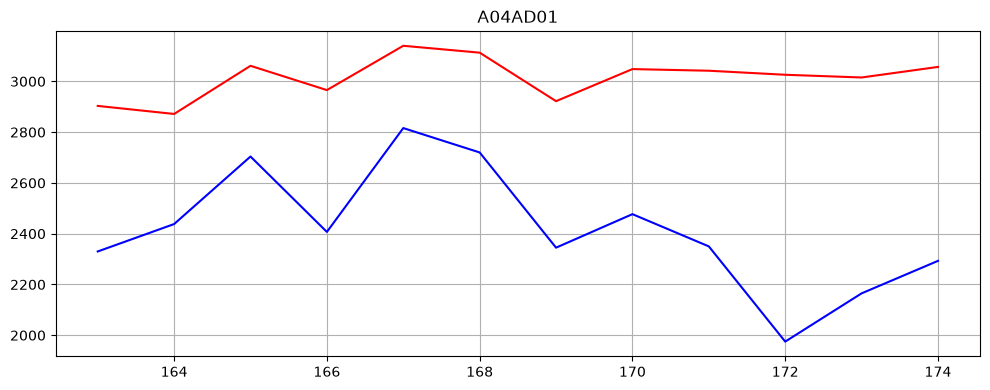

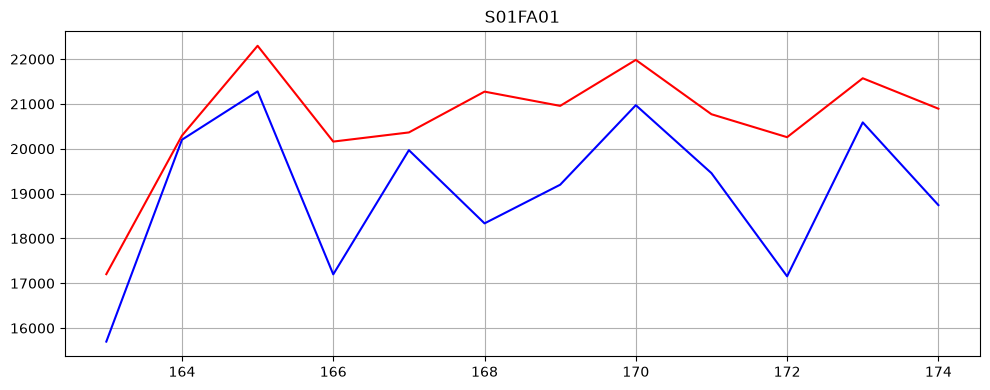

In [10]:
forecast_df = pd.DataFrame(forecasts)

for code in codes:
    plt.figure(figsize=(10,4))
    plt.plot(test_data[code], "b")
    plt.plot(forecast_df[code], "r")
    plt.title(code)
    plt.grid()
    plt.tight_layout()
    plt.show()

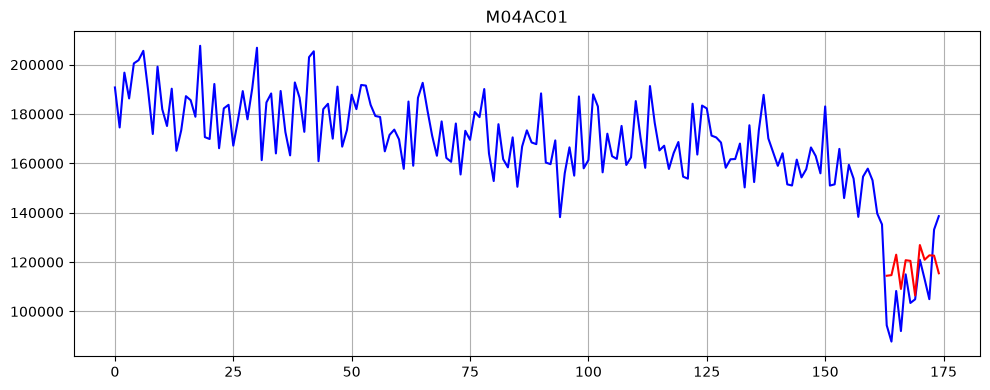

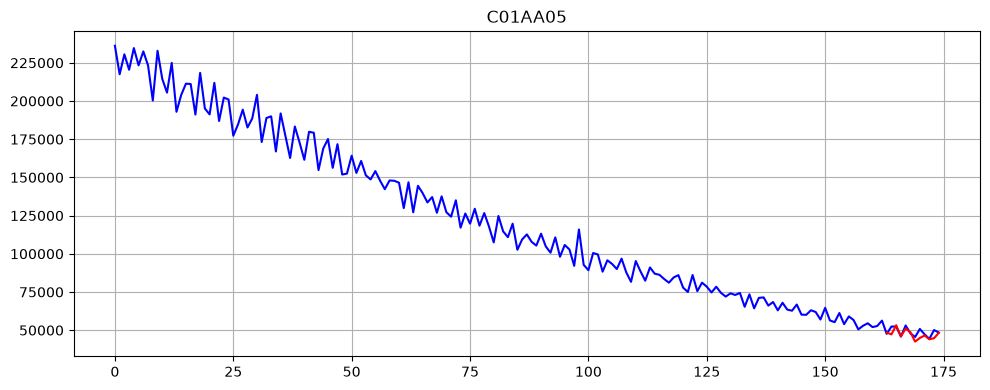

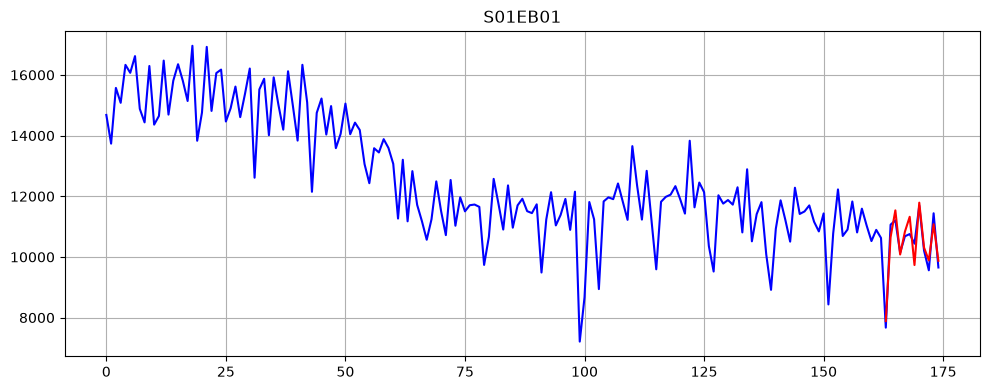

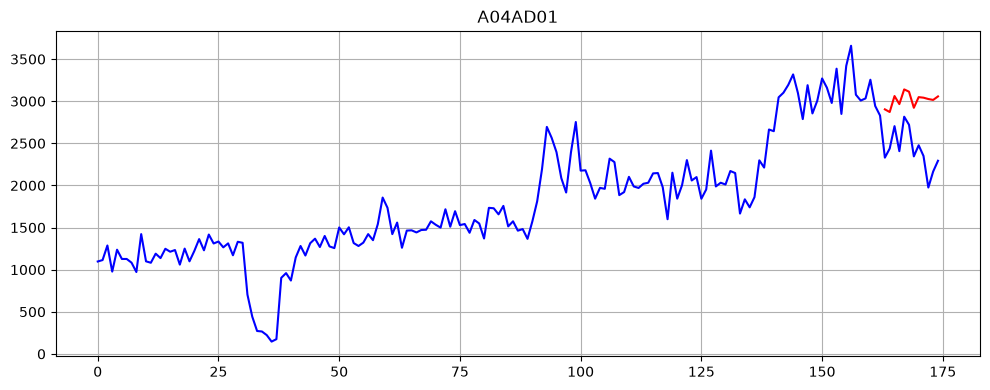

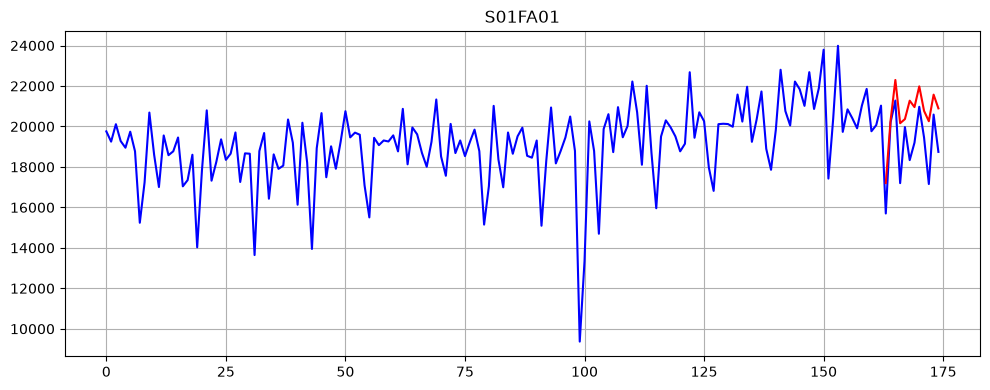

In [11]:
for code in codes:
    plt.figure(figsize=(10,4))
    plt.plot(data[code], "b")
    plt.plot(forecast_df[code], "r")
    plt.title(code)
    plt.grid()
    plt.tight_layout()
    plt.show()

After all, the models seem good enough despite the mid metrics! The 3 models with the very good metrics seem excellent. 

The 2 models with the bad metrics were just tested with unexpected test data. The model for M04AC01 is ok. The model for A04AD01 isn't that good because the data changed vastly. This might have happened due to unpredictable exogenous reasons such as:
- Regulatory decisions: The state decided to change the reimbursement rate for the medication.
- Supply chain: A stockout occurred—either for the medication itself or for a competitor—leading everyone to purchase A04AD01 as a substitute.
- Entry of a generic drug: A cheaper version of the medication was launched, capturing some of its market share.

Unfortunately, there's not a lot we can do about this score and it seems to be a limitation of the project.

### Final training and saving

In [12]:
final_models = {}
final_forecasts = {}

for code in codes:
    print(f"\n==== Final model training on whole dataset for : {code} ====")

    best_order = models[code].order
    best_seasonal_order = models[code].seasonal_order
    
    start_time = time.perf_counter()
    
    final_model = pm.ARIMA(
        order=best_order,
        seasonal_order=best_seasonal_order,
        suppress_warnings=True,
    )

    final_model.fit(data[code])
    final_models[code] = final_model

    final_forecasts[code] = final_model.predict(n_periods=12)

    end_time = time.perf_counter()
    print(f"Training took: {(end_time-start_time):.2f} seconds")

    model_path = MODELS_DIR / Path(f"sarima_{code}.joblib")
    joblib.dump(final_model, model_path)

    print(f"Best parameters: {best_order} x {best_seasonal_order}")
    print(f"Saved at: {model_path}\n")

pd.DataFrame(final_forecasts).to_csv(OUTPUT_DATA_DIR / Path("forecast_in_boxes_12_months.csv"))


==== Final model training on whole dataset for : M04AC01 ====
Training took: 0.98 seconds
Best parameters: (1, 1, 0) x (0, 1, 2, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\models\sarima_M04AC01.joblib


==== Final model training on whole dataset for : C01AA05 ====
Training took: 0.39 seconds
Best parameters: (0, 1, 1) x (0, 1, 0, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\models\sarima_C01AA05.joblib


==== Final model training on whole dataset for : S01EB01 ====
Training took: 8.53 seconds
Best parameters: (3, 1, 3) x (1, 1, 2, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\models\sarima_S01EB01.joblib


==== Final model training on whole dataset for : A04AD01 ====
Training took: 1.91 seconds
Best parameters: (1, 1, 1) x (0, 1, 1, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_E